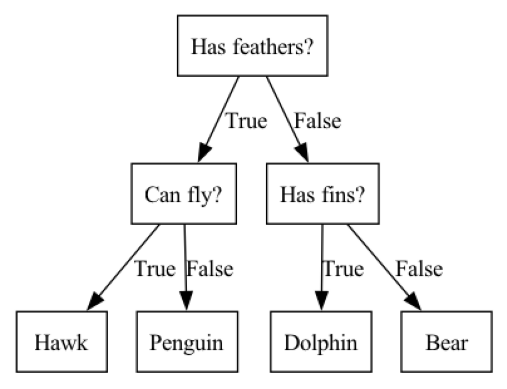

In [2]:
import mglearn 

# 質問を表す木のノードと、答えを表す終端ノードがある
# 3つの特徴量（羽毛があるか、飛べるか、ヒレがあるか）で識別するモデルを生成する
# データの再帰分割は、対象の領域に1つの対象値しか含まれなくなるまで繰り返される

# 過剰適合を防ぐために、事前枝刈り（構築過程で木の生成を早めに止める）と
# 事後枝刈り（情報の少ないノードを削除する）がある
# →外れ値の影響を軽減する（scikit-learnには、事前枝刈りしか実装されていない）
mglearn.plots.plot_animal_tree()

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data,
    cancer.target,
    stratify=cancer.target,
    random_state=42
)
# 事前草刈りなしの決定木を作成する（汎化性能が落ちる傾向がある）
tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

# 事前草刈りあり（過剰適合を回避しやすくなるので、汎化性能を担保しやすい）
tree = DecisionTreeClassifier(max_depth=4, random_state=0)
tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(tree.score(X_test, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.937
Accuracy on training set: 0.988
Accuracy on test set: 0.951


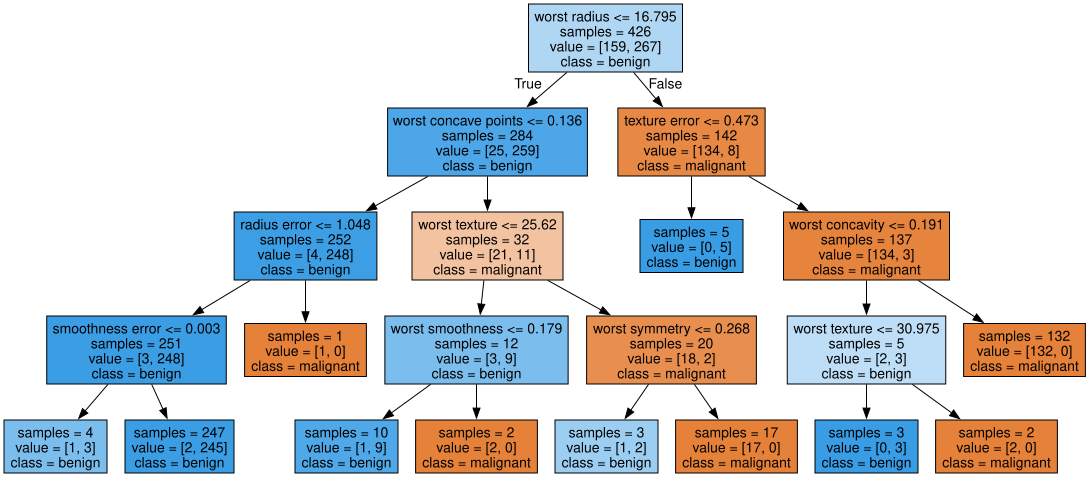

In [4]:
from sklearn.tree import export_graphviz
export_graphviz(
    tree,
    out_file="tree.dot",
    class_names=["malignant", "benign"],
    feature_names=cancer.feature_names,
    impurity=False,
    filled=True
)

import graphviz

with open("tree.dot") as f:
    dot_graph = f.read()
graphviz.Source(dot_graph)

Feature importances:
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.01019737 0.04839825
 0.         0.         0.0024156  0.         0.         0.
 0.         0.         0.72682851 0.0458159  0.         0.
 0.0141577  0.         0.018188   0.1221132  0.01188548 0.        ]


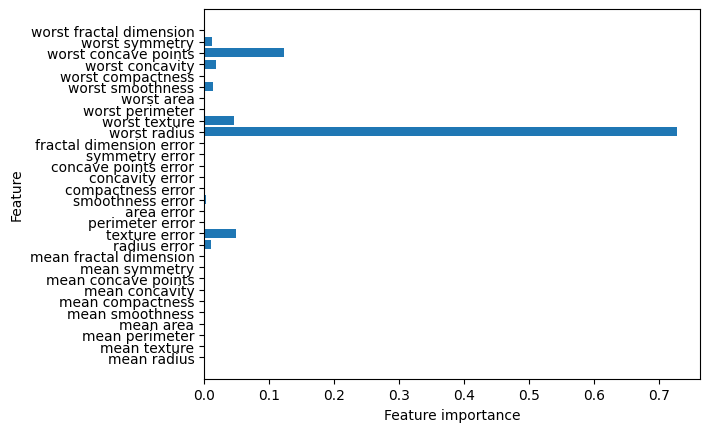

In [5]:
# 特徴量の重要性（0は使われていない、1は使われている、0~1の連続値で表現）
print("Feature importances:\n{}".format(tree.feature_importances_))

import matplotlib.pyplot as plt
import numpy as np

def plot_feature_importances_cancer(model):
    n_features = cancer.data.shape[1]
    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), cancer.feature_names)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")

plot_feature_importances_cancer(tree)

Feature importances: [0. 1.]


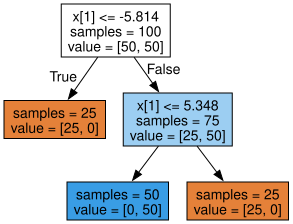

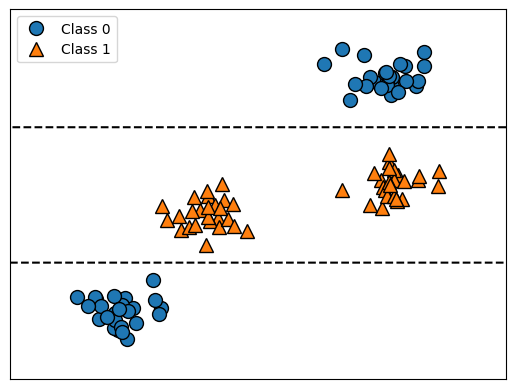

In [6]:
# 特定の値との大小だけで決まるほど、決定木での分類は単純じゃない
tree = mglearn.plots.plot_tree_not_monotone()
display(tree)

Text(0, 0.5, 'Price in $/Mbyte')

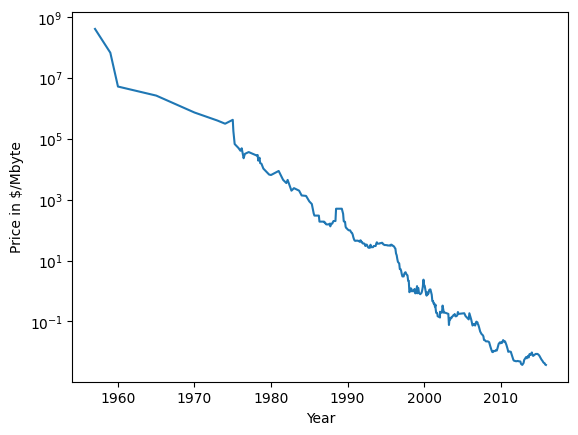

In [7]:
# 決定木による回帰
import os
import pandas as pd

ram_prices = pd.read_csv(os.path.join(mglearn.datasets.DATA_PATH, "ram_price.csv"))

plt.semilogy(ram_prices.date, ram_prices.price)
plt.xlabel("Year")
plt.ylabel("Price in $/Mbyte")

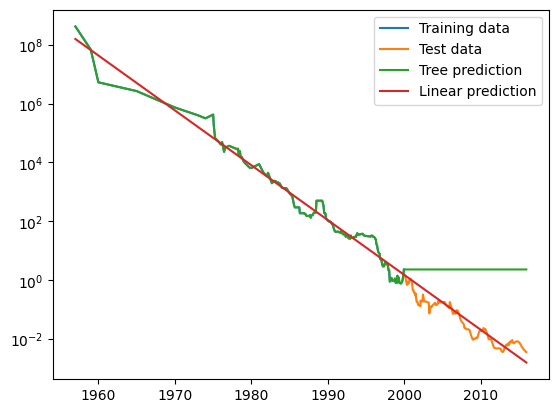

In [11]:
# 回帰と線形モデルでの予測結果の比較
# 決定木はデータを持っていない領域に対して、新しい答えを生成することができない
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

data_train = ram_prices[ram_prices.date < 2000]
data_test = ram_prices[ram_prices.date >= 2000]

X_train = data_train.date.to_numpy()[:, np.newaxis]
y_train = np.log(data_train.price)

tree = DecisionTreeRegressor().fit(X_train, y_train)
linear_reg = LinearRegression().fit(X_train, y_train)

X_all = ram_prices.date.to_numpy()[:, np.newaxis]

pred_tree = tree.predict(X_all)
pred_lr = linear_reg.predict(X_all)

price_tree = np.exp(pred_tree)
price_lr = np.exp(pred_lr)

plt.semilogy(data_train.date, data_train.price, label="Training data")
plt.semilogy(data_test.date, data_test.price, label="Test data")
plt.semilogy(ram_prices.date, price_tree, label="Tree prediction")
plt.semilogy(ram_prices.date, price_lr, label="Linear prediction")
plt.legend()